# Capstone Gate 3 (Part 2): Cleaning, Split and Baselines
Goal: get the data ready and set the scores our final model must beat.

In [14]:
# Import the libraries we need
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import recall_score, f1_score, confusion_matrix

## Part A: Prepare the Data

In [15]:
# Load the CSV file
df = pd.read_csv("athlete_recovery_synthetic.csv")

print("Shape:", df.shape)

Shape: (8379, 19)


In [16]:
# Turn the score into a tier (same as the EDA notebook)
def get_tier(score):
    if score >= 75:
        return "Green"
    elif score >= 40:
        return "Orange"
    else:
        return "Red"

df["Tier"] = df["Recovery_Score"].apply(get_tier)

In [17]:
# New columns
# 1 = sleep was missing, 0 = sleep was recorded 
df["Sleep_Missing"] = df["Sleep_Duration_Hours"].isna().astype(int)

# Stress as numbers: Low = 1, Medium = 2, High = 3
df["Stress_Num"] = df["Stress_Level"].map({"Low": 1, "Medium": 2, "High": 3})

# Training load = duration x intensity
df["Training_Load"] = df["Training_Duration_Min"] * df["Training_Intensity"]

**Note:** The inputs below do NOT include Recovery_Score (it is the answer), Mood or Energy (they may leak), or Gender.

In [18]:
# Choose the inputs (X) and the target (y)
features = ["Sleep_Duration_Hours", "Sleep_Missing", "Stress_Num", "HRV_ms",
            "Resting_Heart_Rate", "Muscle_Soreness", "Caffeine_Intake_mg",
            "Training_Duration_Min", "Training_Intensity", "Training_Load"]

X = df[features]
y = df["Tier"]

## Part B: Split by Athlete

Each athlete has about 28 days that look alike. If we split by random rows, the same athlete would be in both train and test, and our scores would look too good. So we split the **athletes**, not the rows.

In [19]:
# Split the athlete IDs 80% train / 20% test
athlete_ids = df["Athlete_ID"].unique()
train_ids, test_ids = train_test_split(athlete_ids, test_size=0.2, random_state=42)

# Rows that belong to each group
train_rows = df["Athlete_ID"].isin(train_ids)
X_train, y_train = X[train_rows], y[train_rows]
X_test, y_test = X[~train_rows], y[~train_rows]

print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Athletes in train:", len(train_ids), "| Athletes in test:", len(test_ids))
print()
print("Train tiers (%):")
print((y_train.value_counts(normalize=True) * 100).round(1))
print("Test tiers (%):")
print((y_test.value_counts(normalize=True) * 100).round(1))

Train rows: 6705 | Test rows: 1674
Athletes in train: 240 | Athletes in test: 60

Train tiers (%):
Tier
Orange    41.0
Red       38.9
Green     20.0
Name: proportion, dtype: float64
Test tiers (%):
Tier
Orange    41.6
Red       38.5
Green     20.0
Name: proportion, dtype: float64


## Part C: Fill Missing Values

In [20]:
# Median of each column, using the TRAIN data only
medians = X_train.median()

# Fill the blanks in both sets with those train medians
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Missing left in train:", X_train.isna().sum().sum())
print("Missing left in test: ", X_test.isna().sum().sum())

Missing left in train: 0
Missing left in test:  0


**Why train only?** The test set must act like new data we have never seen, so we do not use it to calculate anything.

## Part D: Baseline Models

Our two scores:
- **Red recall:** of the days that are really Red, how many did we catch? 
- **Macro F1:** one score that treats Red, Orange and Green equally.

In [21]:
# A small helper to score each model and save the results
results = []

def score_model(name, y_pred):
    red_recall = recall_score(y_test, y_pred, labels=["Red"], average=None)[0]
    macro_f1 = f1_score(y_test, y_pred, average="macro")
    results.append({"Model": name, "Red recall": round(red_recall, 3), "Macro F1": round(macro_f1, 3)})
    print(name, "| Red recall:", round(red_recall, 3), "| Macro F1:", round(macro_f1, 3))

In [22]:
# Baseline 1: always guess the most common tier in the train data
most_common = y_train.value_counts().idxmax()
print("Most common tier:", most_common)

pred_1 = [most_common] * len(y_test)
score_model("1. Always most common", pred_1)

Most common tier: Orange
1. Always most common | Red recall: 0.0 | Macro F1: 0.196


In [23]:
# Baseline 2: a simple rule, like a coach might use
# One flag for each warning sign
hrv_low = X_train["HRV_ms"].quantile(0.25)
sore_high = X_train["Muscle_Soreness"].quantile(0.75)

flags = ((X_test["HRV_ms"] < hrv_low).astype(int)
         + (X_test["Sleep_Duration_Hours"] < 7).astype(int)
         + (X_test["Muscle_Soreness"] > sore_high).astype(int)
         + (X_test["Stress_Num"] == 3).astype(int))

# 0 flags = Green, 1 flag = Orange, 2 or more flags = Red
def rule_tier(n):
    if n == 0:
        return "Green"
    elif n == 1:
        return "Orange"
    else:
        return "Red"

pred_2 = flags.apply(rule_tier)
score_model("2. Simple rule", pred_2)

2. Simple rule | Red recall: 0.545 | Macro F1: 0.541


In [24]:
# Baseline 3: Logistic Regression
model = Pipeline([
    ("scale", StandardScaler()),          # put columns on the same scale
    ("logreg", LogisticRegression(max_iter=1000))
])
model.fit(X_train, y_train)

pred_3 = model.predict(X_test)
score_model("3. Logistic Regression", pred_3)

3. Logistic Regression | Red recall: 0.865 | Macro F1: 0.836


In [25]:
# Compare all three
print(pd.DataFrame(results))

                    Model  Red recall  Macro F1
0   1. Always most common       0.000     0.196
1          2. Simple rule       0.545     0.541
2  3. Logistic Regression       0.865     0.836


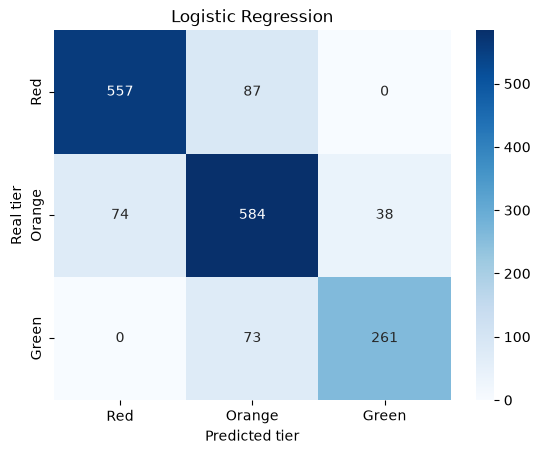

In [26]:
# Confusion matrix for Logistic Regression
order = ["Red", "Orange", "Green"]
cm = confusion_matrix(y_test, pred_3, labels=order)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=order, yticklabels=order)
plt.xlabel("Predicted tier")
plt.ylabel("Real tier")
plt.title("Logistic Regression")
plt.show()

**Explain:** What do the baseline results tell us?

- **Always most common** never says Red, so its Red recall is 0. This is the lowest bar.
- **Simple rule** catches about 55% of the Red days (Macro F1 about 0.54). It is better than guessing, but it misses almost half of the Red days.
- **Logistic Regression** is much better: Red recall about 0.87 and Macro F1 about 0.84. It catches about 87% of the Red days.
- In the confusion matrix, the model never mixes up Red and Green. Its mistakes are between neighbouring tiers (Red vs Orange, and Orange vs Green), which are less serious.

**Our target for the next step:** beat Logistic Regression on Red recall and Macro F1 with a Decision Tree and a Random Forest (Gate 4).